# 그리드서치

In [2]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression 
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import PolynomialFeatures,StandardScaler  
from sklearn.model_selection import train_test_split
from scipy.special import expit, softmax    # expit:이진분류,softmax:다중분류 0-1 숫자로 변환
from sklearn.linear_model import SGDClassifier
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.model_selection import cross_validate,StratifiedKFold,GridSearchCV

In [3]:
#데이터 불러오기
wine =pd.read_csv('data/wine.csv')
wine.head(2)

,alcohol,sugar,pH,class
0,9.4,1.9,3.51,0.0
1,9.8,2.6,3.20,0.0


In [4]:
wine.info()
wine.describe()

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   alcohol  6497 non-null   float64
 1   sugar    6497 non-null   float64
 2   pH       6497 non-null   float64
 3   class    6497 non-null   float64
dtypes: float64(4)
memory usage: 203.2 KB


,alcohol,sugar,pH,class
count,6497.000000,6497.000000,6497.000000,6497.000000
mean,10.491801,5.443235,3.218501,0.753886
std,1.192712,4.757804,0.160787,0.430779
min,8.000000,0.600000,2.720000,0.000000
25%,9.500000,1.800000,3.110000,1.000000
50%,10.300000,3.000000,3.210000,1.000000
75%,11.300000,8.100000,3.320000,1.000000
max,14.900000,65.800000,4.010000,1.000000


<Axes: >

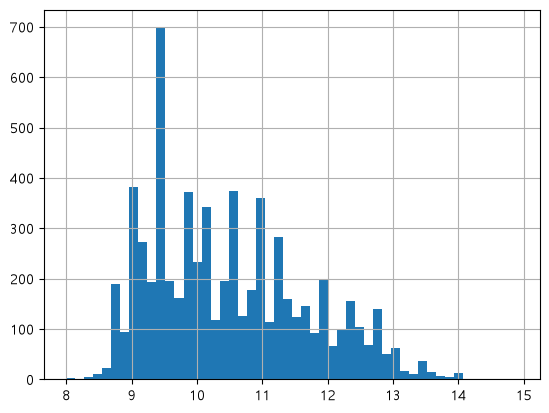

In [5]:
# 히스토그램 - 피처컬럼에 대한 분포도 볼 수 있음.
wine['alcohol'].hist(bins=50)      #bins = 구간(칸)의 개수

<Axes: >

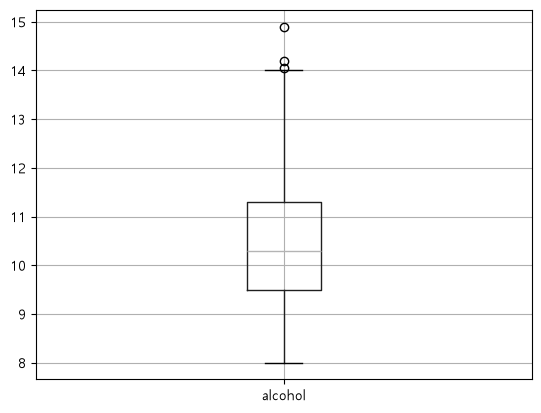

In [6]:
# 데이터 분포를 4개의 대표값으로 요약해서 상자 모양으로 그린 그래프
wine.boxplot(column=['alcohol'])

In [7]:
wine.columns

Index(['alcohol', 'sugar', 'pH', 'class'], dtype='str')

In [8]:
wine2= wine[['alcohol', 'sugar', 'pH']]
wine2.head(2)

,alcohol,sugar,pH
0,9.4,1.9,3.51
1,9.8,2.6,3.20


In [9]:
def plot_hist(wine2):
    plt.rcParams['figure.figsize'] = [20,10]   #그래프 크기 가로20,세로 16
    fig = plt.figure(1)                        #전체 그래프 1개를 생성
    for i in range(len(wine2.columns)):        #컬럼개수만큼 3번 반복
        ax = fig.add_subplot(1,3,i+1)          #(행 수, 열 수 ,몇 번쨰 칸)
        plt.hist(wine2[wine2.columns[i]],bins=50)
        ax.set_title(wine2.columns[i])
    plt.show()

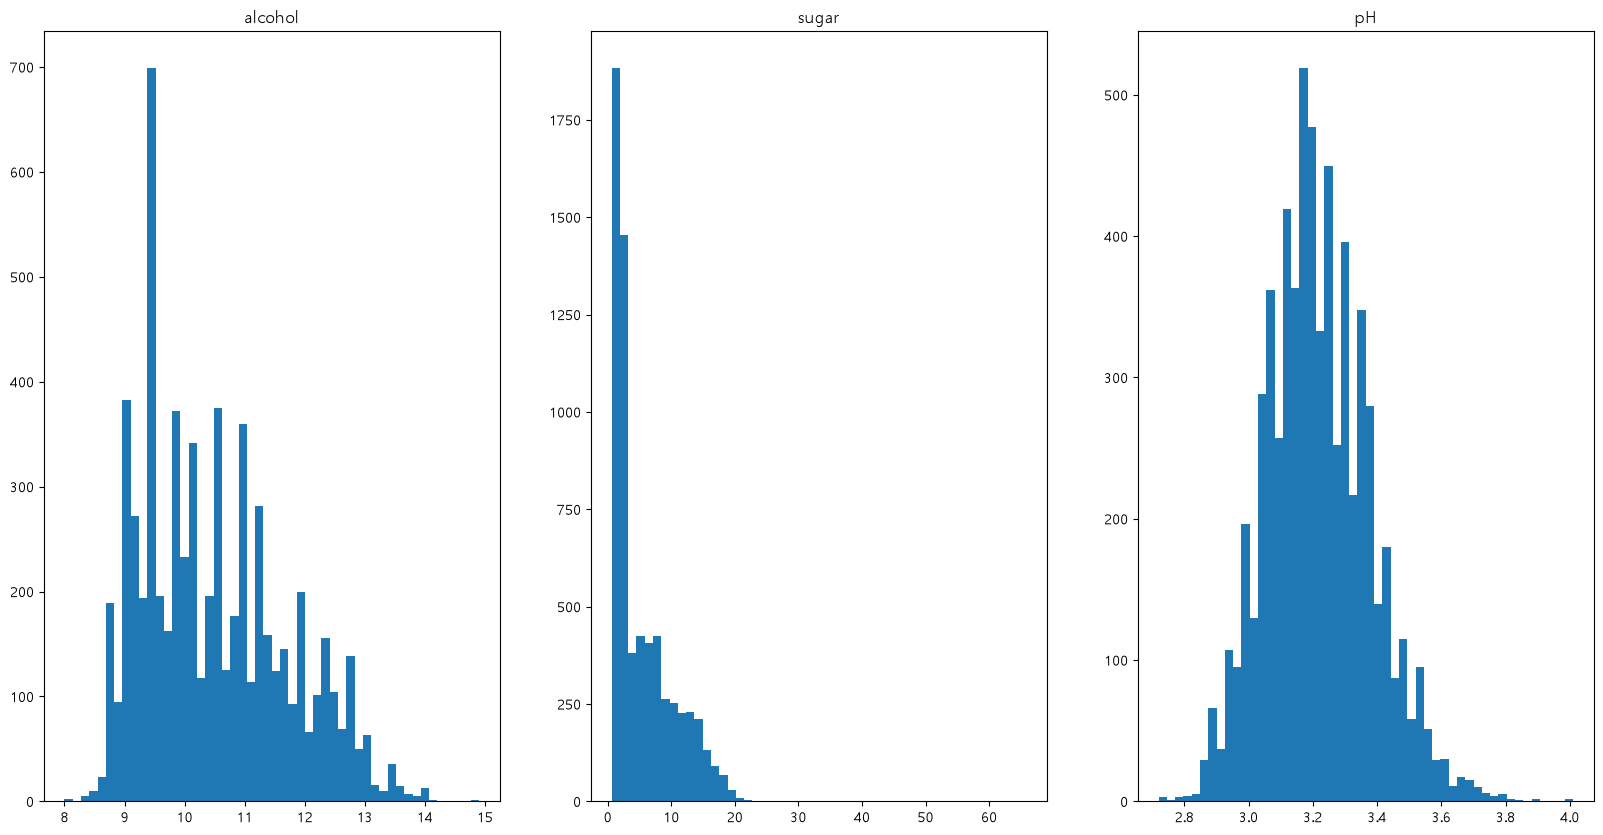

In [10]:
plot_hist(wine2)

데이터 전처리 작업
- None데이터 유무
- None 데이터를 어떻게 처리 할것인지 : 삭제,평균,0 대체
- 정규화 작업을 해야 하는지
- 원핫인코딩 작업을 해야 하는지
- 다중공선성이 있는지 

In [11]:
# data,label 저장
data = wine[wine.columns[:-1]].values
label = wine['class'].values

#데이터분리
train_data,test_data,train_label,test_label = \
    train_test_split(data,label,test_size=0.2,random_state=42)       #test_size : 훈련 데이터 80%, 테스트데이터:20%

In [12]:
dt = DecisionTreeClassifier(max_depth=3,random_state=42)
dt.fit(train_data,train_label)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

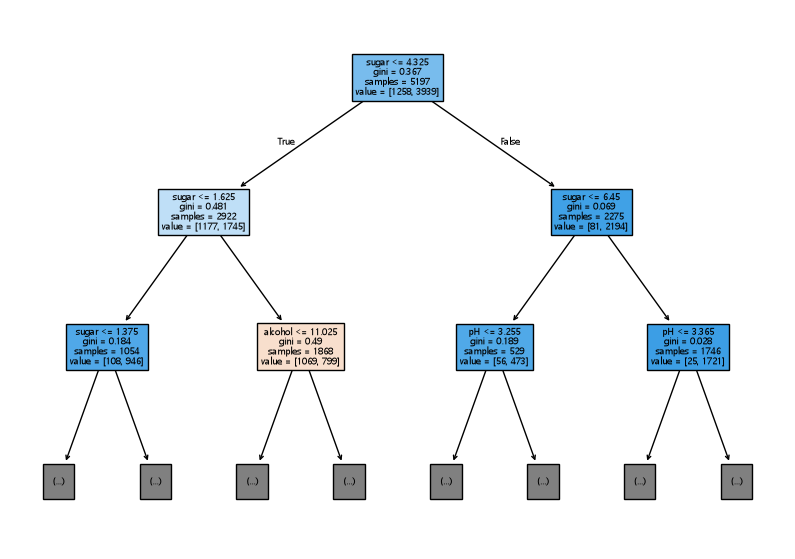

In [13]:
plt.figure(figsize=(10,7))
# max_depth : tree의 깊이 개수, filled=True:1,0에 대해 색상 넣기(0:주황,1:파랑)
plot_tree(dt,max_depth=2,filled=True,feature_names=['alcohol','sugar','pH'])
plt.show()

In [15]:
# decrease = 0.0001,0.001 
# max_depth : range(5,20) 
# min_sample_split : range(2,100,10)
for i in np.arange(0.0001,0.001,0.0001):
    dt = DecisionTreeClassifier(min_impurity_decrease=i, min_samples_split=2 ,max_depth=1,random_state=42)
    dt.fit(train_data,train_label)
    print(i)
    print('train정확도',dt.score(train_data,train_label))
    print('test정확도',dt.score(test_data,test_label))

0.0001
train정확도 0.7579372715027901
test정확도 0.7376923076923076
0.0002
train정확도 0.7579372715027901
test정확도 0.7376923076923076
0.00030000000000000003
train정확도 0.7579372715027901
test정확도 0.7376923076923076
0.0004
train정확도 0.7579372715027901
test정확도 0.7376923076923076
0.0005
train정확도 0.7579372715027901
test정확도 0.7376923076923076
0.0006000000000000001
train정확도 0.7579372715027901
test정확도 0.7376923076923076
0.0007000000000000001
train정확도 0.7579372715027901
test정확도 0.7376923076923076
0.0008
train정확도 0.7579372715027901
test정확도 0.7376923076923076
0.0009000000000000001
train정확도 0.7579372715027901
test정확도 0.7376923076923076


In [14]:
print('train정확도',dt.score(train_data,train_label))
print('test정확도',dt.score(test_data,test_label))

train정확도 0.8454877814123533
test정확도 0.8415384615384616
